In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from transformers import pipeline
from transformers import BertTokenizer

In [ ]:
import kagglehub
from pathlib import Path

# Mental Health Corpus (27,977 posts), downloaded once to the kagglehub cache
MH_DIR = Path(kagglehub.dataset_download("reihanenamdari/mental-health-corpus"))
df = pd.read_csv(MH_DIR / "mental_health.csv")

In [ ]:
print(df.head())

                                                text  label
0  dear american teens question dutch person hear...      0
1  nothing look forward lifei dont many reasons k...      1
2  music recommendations im looking expand playli...      0
3  im done trying feel betterthe reason im still ...      1
4  worried  year old girl subject domestic physic...      1


In [ ]:
print(df.size)
print(df.shape)

55954
(27977, 2)


In [ ]:
print(pd.DataFrame(np.unique(df['label'], return_counts=True), index=['value', 'count']))

           0      1
value      0      1
count  14139  13838


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27977 entries, 0 to 27976
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    27977 non-null  object
 1   label   27977 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 437.3+ KB


In [ ]:
print(df.isnull().sum())

text     0
label    0
dtype: int64


<ipython-input-8-c4fbb4c8b315>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='rocket_r')


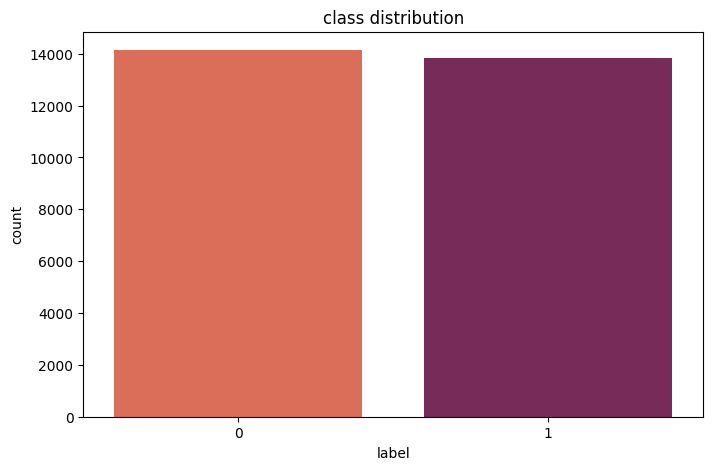

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', palette='rocket_r')
plt.xlabel('label')
plt.ylabel('count')
plt.title('class distribution')
plt.show()

In [ ]:
x = df.text
y = df.label

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
custom_stopwords = [
    'i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd",
    'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself',
    'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this',
    'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had',
    'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while',
    'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above',
    'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once',
    'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some',
    'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 'very', 's', 't', 'can', 'will', 'just', 'don',
    "don't", 'should', "should've", 'now', 'd', 'll', 'm', 'o', 're', 've', 'y', 'ain', 'aren', "aren't", 'couldn', "couldn't",
    'didn', "didn't", 'doesn', "doesn't", 'hadn', "hadn't", 'hasn', "hasn't", 'haven', "haven't", 'isn', "isn't", 'ma', 'mightn',
    "mightn't", 'mustn', "mustn't", 'needn', "needn't", 'shan', "shan't", 'shouldn', "shouldn't", 'wasn', "wasn't", 'weren',
    "weren't", 'won', "won't", 'wouldn', "wouldn't"
]

df['text'] = df['text'].str.lower()
df['text'] = df['text'].str.replace(r'[^\w\s]+', '', regex=True)
df['text'] = df['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in custom_stopwords]))
df['text'] = df['text'].apply(lambda x: tokenizer.tokenize(x))

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

In [ ]:
print(df.head())

                                                text  label
0  [dear, american, teens, question, dutch, perso...      0
1  [nothing, look, forward, life, ##i, don, ##t, ...      1
2  [music, recommendations, im, looking, expand, ...      0
3  [im, done, trying, feel, better, ##the, reason...      1
4  [worried, year, old, girl, subject, domestic, ...      1


In [ ]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.4, random_state=42)

In [ ]:
analyzer = 'word'
ngram_range = (1, 5)
min_df = 3
max_df = 0.8
max_features = 5000
stop_words = 'english'
sublinear_tf = True

In [ ]:
svm = Pipeline([('tfidf', TfidfVectorizer(
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=max_df,
        max_features=max_features,
        stop_words=stop_words,
        sublinear_tf=sublinear_tf
    )),
    ('svmc', SVC(kernel="rbf", random_state=42))
])

In [ ]:
svm.fit(x_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.8, max_features=5000, min_df=3,
                                 ngram_range=(1, 5), stop_words='english',
                                 sublinear_tf=True)),
                ('svmc', SVC(random_state=42))])

In [ ]:
y_val_pred = svm.predict(x_val)
validation_accuracy = accuracy_score(y_val, y_val_pred)
print("Validation Accuracy:", validation_accuracy)

Validation Accuracy: 0.9201668156091749


In [ ]:
y_test_pred = svm.predict(x_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.9280928986154533


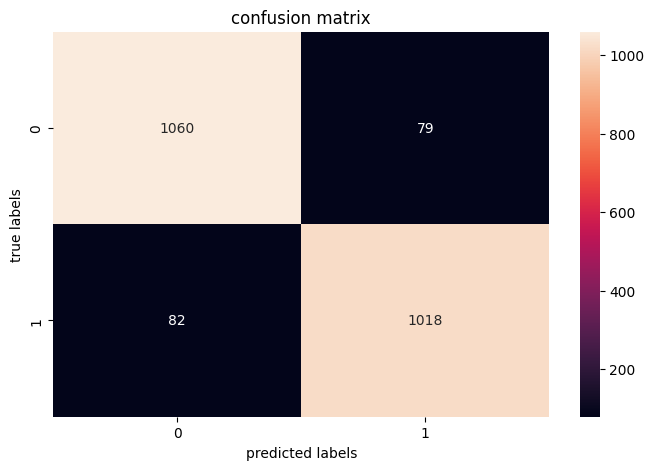

In [ ]:
c_matrix = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 5))
class_names = df['label'].unique()
sns.heatmap(c_matrix, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("predicted labels")
plt.ylabel("true labels")
plt.title("confusion matrix")
plt.show()

In [ ]:
report = classification_report(y_test, y_test_pred)
print(report)

              precision    recall  f1-score   support

           0       0.93      0.93      0.93      1139
           1       0.93      0.93      0.93      1100

    accuracy                           0.93      2239
   macro avg       0.93      0.93      0.93      2239
weighted avg       0.93      0.93      0.93      2239

